In [81]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [82]:
transform = transforms.ToTensor()

In [83]:
train_data = datasets.MNIST("./Data", train=True, download=True, transform=transform)
test_data = datasets.MNIST("./Data", train=False, download=True, transform=transform)

In [84]:
train_loader = DataLoader(train_data, batch_size=10, shuffle=True)
test_loader = DataLoader(test_data, batch_size=10, shuffle=False)

In [85]:
conv1 = nn.Conv2d(1, 6, 3, 1)
conv2 = nn.Conv2d(6, 16, 3, 1)

In [86]:
for i, (X_train, y_train) in enumerate(train_loader):
    break

In [87]:
X_train.shape

torch.Size([10, 1, 28, 28])

In [88]:
x1 = F.relu(conv1(X_train))
x1.shape

torch.Size([10, 6, 26, 26])

In [89]:
x1 = F.max_pool2d(x1, 2, 2)
x1.shape

torch.Size([10, 6, 13, 13])

In [90]:
x2 = F.relu(conv2(x1))
x2.shape

torch.Size([10, 16, 11, 11])

In [91]:
x2 = F.max_pool2d(x2, 2, 2)
x2.shape

torch.Size([10, 16, 5, 5])

In [92]:
x = x2.view(len(x2), 16 * 5 * 5)
x.shape

torch.Size([10, 400])

In [93]:
type(x2.shape)

torch.Size

In [94]:
x2.shape[1:].numel()

400

In [95]:
x2.ndim

4

In [96]:
X = x2.view(x2.shape[0], x2.shape[1:].numel())
X.shape

torch.Size([10, 400])

In [97]:
class ConvolusionalNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 3)
        self.conv2 = nn.Conv2d(6, 16, 3)
        self.fc1 = nn.Linear(5 * 5 * 16, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, X):
        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2)
        X = X.view(len(X), -1)
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X

In [98]:
torch.manual_seed(42)
model = ConvolusionalNetwork()
model

ConvolusionalNetwork(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [99]:
total = 0
for name, param in model.named_parameters():
    print(name)
    print(param.numel(), param.shape, "\n")
    total += param.numel()

print(total)

conv1.weight
54 torch.Size([6, 1, 3, 3]) 

conv1.bias
6 torch.Size([6]) 

conv2.weight
864 torch.Size([16, 6, 3, 3]) 

conv2.bias
16 torch.Size([16]) 

fc1.weight
48000 torch.Size([120, 400]) 

fc1.bias
120 torch.Size([120]) 

fc2.weight
10080 torch.Size([84, 120]) 

fc2.bias
84 torch.Size([84]) 

fc3.weight
840 torch.Size([10, 84]) 

fc3.bias
10 torch.Size([10]) 

60074


In [100]:
criterion = nn.CrossEntropyLoss()
optimizers = torch.optim.Adam(model.parameters(), lr=0.001)

In [101]:
import time

start_time = time.time()

# variables
epochs = 5
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# For loop epochs
for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    # train
    for b, (X_train, y_train) in enumerate(train_loader):
        b += 1

        y_pred = model(X_train)  # no flatten
        loss = criterion(y_pred, y_train)
        predicted = torch.max(y_pred.data, 1)[1]
        trn_corr += (predicted == y_train).sum()

        optimizers.zero_grad()
        loss.backward()
        optimizers.step()

        if b % 600 == 0:
            acc = trn_corr * 100 / len(X_train) / b
            print(
                f"Epoch: {i + 1} Batch: {b} loss: {loss.item():2.5f} accuracy: {acc:2.2f}"
            )

    train_losses.append(loss.item())
    train_correct.append(trn_corr)

    # validation
    with torch.no_grad():
        for b, (X_test, y_test) in enumerate(test_loader):
            y_val = model(X_test)
            predicted = torch.max(y_val.data, 1)[1]
            tst_corr += (predicted == y_test).sum()

    loss = criterion(y_val, y_test)
    test_losses.append(loss.item())
    test_correct.append(tst_corr)

during = time.time() - start_time
mins = during // 60
secs = during - mins * 60
print(f"Traning took {mins:2.0f}:{secs:2.0f}")

Epoch: 1 Batch: 600 loss: 0.04255 accuracy: 78.48
Epoch: 1 Batch: 1200 loss: 0.07606 accuracy: 85.82
Epoch: 1 Batch: 1800 loss: 0.36374 accuracy: 88.66
Epoch: 1 Batch: 2400 loss: 0.02648 accuracy: 90.48
Epoch: 1 Batch: 3000 loss: 0.00863 accuracy: 91.64
Epoch: 1 Batch: 3600 loss: 0.00133 accuracy: 92.49
Epoch: 1 Batch: 4200 loss: 0.54266 accuracy: 93.14
Epoch: 1 Batch: 4800 loss: 0.03397 accuracy: 93.62
Epoch: 1 Batch: 5400 loss: 0.01119 accuracy: 94.03
Epoch: 1 Batch: 6000 loss: 0.03738 accuracy: 94.31
Epoch: 2 Batch: 600 loss: 0.05375 accuracy: 97.80
Epoch: 2 Batch: 1200 loss: 0.04017 accuracy: 97.82
Epoch: 2 Batch: 1800 loss: 0.00176 accuracy: 97.83
Epoch: 2 Batch: 2400 loss: 0.03233 accuracy: 97.80
Epoch: 2 Batch: 3000 loss: 0.31514 accuracy: 97.81
Epoch: 2 Batch: 3600 loss: 0.00024 accuracy: 97.84
Epoch: 2 Batch: 4200 loss: 0.00078 accuracy: 97.89
Epoch: 2 Batch: 4800 loss: 0.00059 accuracy: 97.89
Epoch: 2 Batch: 5400 loss: 0.00303 accuracy: 97.89
Epoch: 2 Batch: 6000 loss: 0.0314

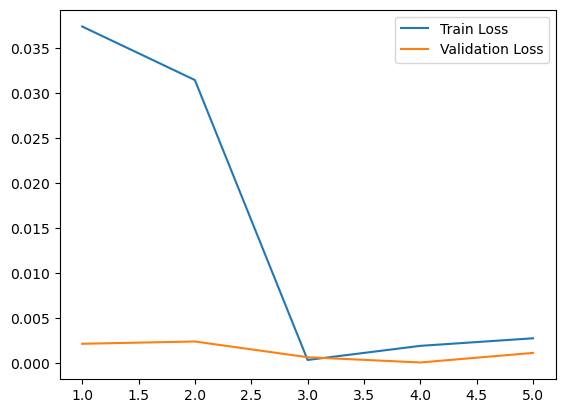

In [102]:
plt.plot(range(1, epochs + 1), train_losses, label="Train Loss")
plt.plot(range(1, epochs + 1), test_losses, label="Validation Loss")
plt.legend()

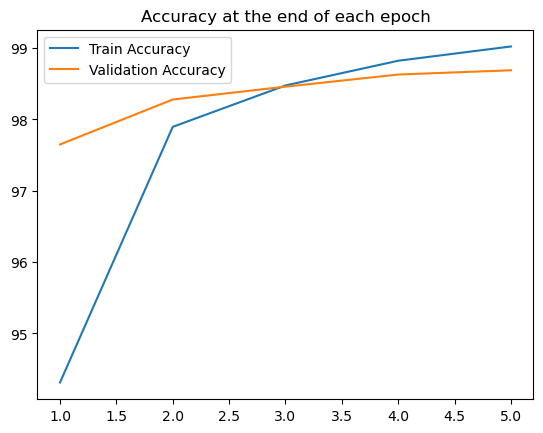

In [103]:
plt.plot(
    range(1, epochs + 1),
    np.array(train_correct) * 100 / len(train_data),
    label="Train Accuracy",
)
# plt.plot(range(1,epochs+1), np.array(train_correct)/600, label = "Train Accuracy")
plt.plot(
    range(1, epochs + 1),
    np.array(test_correct) * 100 / len(test_data),
    label="Validation Accuracy",
)
# plt.plot(range(1,epochs+1), np.array(test_correct)/100, label = "Validation Accuracy")
plt.title("Accuracy at the end of each epoch")
plt.legend()

In [104]:
test_load_all = DataLoader(test_data, batch_size=len(test_data), shuffle=False)

In [ ]:
with torch.no_grad():
    correct = 0
    for X_test, y_test in test_load_all:
        y_val = model(X_test)
        predicted = torch.max(y_val.data, 1)[1]
        correct += (predicted == y_test).sum()
        X_incorrect = X_test[predicted != y_test]
        y_incorrect = y_test[predicted != y_test]

In [ ]:
correct.item() / len(test_data) * 100

98.69

In [ ]:
np.set_printoptions(formatter=dict(int=lambda x: f"{x:4}"))
print(np.arange(10).reshape(1, 10))
print()
print(confusion_matrix(predicted.view(-1), y_test.view(-1)))

[[   0    1    2    3    4    5    6    7    8    9]]

[[ 972    1    1    0    0    2    2    0    2    0]
 [   0 1128    1    0    0    0    3    2    0    0]
 [   2    0 1003    0    1    0    1    3    1    0]
 [   0    3   14 1004    0   10    0    3    3    0]
 [   0    1    1    0  977    0    1    2    0    5]
 [   0    0    0    3    0  872    2    0    2    3]
 [   4    1    0    0    0    1  947    0    0    0]
 [   1    0    6    1    0    1    0 1010    1    3]
 [   1    1    6    1    0    0    2    1  962    4]
 [   0    0    0    1    4    6    0    7    3  994]]


  Correct label:  [   9    9    5    5    9    1    9    7    4    9    8    5]
inCorrect label:  [   8    5    9    3    7    3    4    8    9    4    0    3]


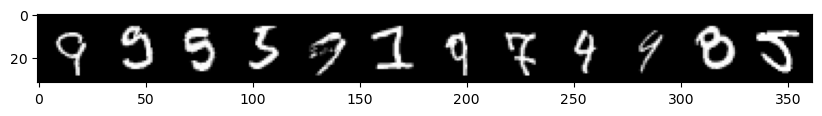

In [ ]:
choose = torch.randint(len(y_incorrect), size=(1, 12)).view(-1)

y_incorrect_grid = []

with torch.no_grad():
    for i in choose:
        new_pred = model(X_incorrect[i].view(1, 1, 28, 28))
        y_incorrect_grid.append(new_pred.argmax().item())

print("  Correct label: ", y_incorrect[choose].numpy())
print("inCorrect label: ", np.array(y_incorrect_grid))

im = make_grid(X_incorrect[choose], nrow=12)


plt.figure(figsize=(10, 4))

# plt.imshow(np.transpose(im.numpy(), (1, 2, 0)))
plt.imshow(im.permute(1, 2, 0))

In [135]:
im.shape

torch.Size([3, 32, 362])

In [146]:
choose[7]

tensor(18)

In [ ]:
image = X_incorrect[choose[7]]
image = image.view(28, 28)

In [148]:
label = y_incorrect[choose[7].item()]
label

tensor(6)

5


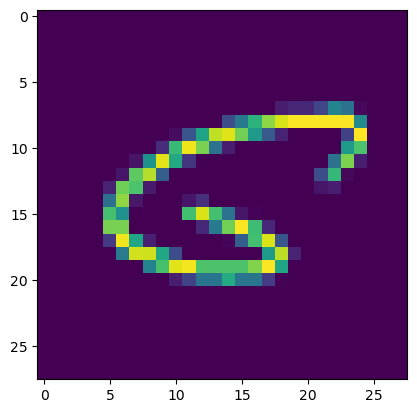

In [ ]:
model.eval()
with torch.no_grad():
    new_pred = model(image.view(1, 1, 28, 28))
    print(new_pred.argmax().item())

plt.imshow(image);

In [109]:
# class myCNN(nn.Module):
#     def __init__(self, out_szs=10, layers=[120, 84]):
#         super().__init__()
#         # self.conv1 = nn.Conv2d(1, 6, kernel_size=(3,2), stride = (1,2))
#         # self.conv2 = nn.Conv2d(6, 16, (5,3))
#         self.conv1 = nn.Conv2d(1, 6, 3)
#         self.conv2 = nn.Conv2d(6, 16, 3)
#         self.adaptive_pool = nn.AdaptiveAvgPool2d((5, 5))
#         self.fc1 = nn.LazyLinear(layers[0])
#         self.fc2 = nn.Linear(layers[0], layers[1])
#         self.fc3 = nn.Linear(layers[1], out_szs)

#     def forward(self, X):
#         X = F.relu(self.conv1(X))
#         X = F.max_pool2d(X, 2, 2)
#         X = F.relu(self.conv2(X))
#         X = F.max_pool2d(X, 2, 2)
#         X = self.adaptive_pool(X)
#         X = X.view(X.shape[0], -1)
#         X = F.relu(self.fc1(X))
#         X = F.relu(self.fc2(X))
#         X = self.fc3(X)

#         return X

In [110]:
# model = myCNN()
# model

In [111]:
# total = 0
# for name, param in model.named_parameters():
#     print(f"In layer {name}:{param.shape}")
#     total += param.numel()

# print("\n", total)

In [112]:
# print(model.conv1.weight.shape)